# EDA & Data Cleaning Guide: Airbnb NYC (Solution)

Answer each question in the cell below it. Work on `df`, not on `data`.

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [35]:
file_id = '1peouHQxfqJnve-Qd62gplsAHSBpPKX9v'
url = f"https://drive.google.com/uc?export=download&id={file_id}"

data = pd.read_csv(url)
data = data[['minimum nights', 'number of reviews', 'reviews per month',
             'neighbourhood group', 'price', 'room type', 'house_rules']]

df = data.copy()
df.head()

/tmp/ipykernel_1451/534559470.py:4: DtypeWarning: Columns (25) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(url)


,minimum nights,number of reviews,reviews per month,neighbourhood group,price,room type,house_rules
0,10.0,9.0,0.21,Brooklyn,$966,Private room,Clean up and treat the home the way you'd like...
1,30.0,45.0,0.38,Manhattan,$142,Entire home/apt,Pet friendly but please confirm with me if the...
2,3.0,0.0,NaN,Manhattan,$620,Private room,"I encourage you to use my kitchen, cooking and..."
3,30.0,270.0,4.64,Brooklyn,$368,Entire home/apt,NaN
4,10.0,9.0,0.10,Manhattan,$204,Entire home/apt,"Please no smoking in the house, porch or on th..."


## 1. First look
How many rows and columns does the dataset have? What does each column represent?

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102599 entries, 0 to 102598
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   minimum nights       102190 non-null  float64
 1   number of reviews    102416 non-null  float64
 2   reviews per month    86720 non-null   float64
 3   neighbourhood group  102570 non-null  object 
 4   price                102352 non-null  object 
 5   room type            102599 non-null  object 
 6   house_rules          50468 non-null   object 
dtypes: float64(3), object(4)
memory usage: 5.5+ MB


In [37]:
df.shape

(102599, 7)

## 2. Data types
Check the data type of every column. Does each type match what the column represents? Fix any column that doesn't.

In [38]:
df['price'] = df['price'].str.strip('$')
df['price'] = df['price'].str.replace(',','')
df['price'] = df['price'].astype('float')

In [39]:
df['price'].isnull().sum()

np.int64(247)

## 3. Categorical columns
Look at the unique values of the categorical columns. Are the categories correct and consistent? What problems could appear, and how would you fix them?

In [40]:
df.describe(include='object')

,neighbourhood group,room type,house_rules
count,102570,102599,50468
unique,7,4,1976
top,Manhattan,Entire home/apt,#NAME?
freq,43792,53701,2712


In [41]:
cat = ['neighbourhood group',	'room type']
for col in cat:
  print(df[col].unique())
  print('------------------------')

['Brooklyn' 'Manhattan' 'brookln' 'manhatan' 'Queens' nan 'Staten Island'
 'Bronx']
------------------------
['Private room' 'Entire home/apt' 'Shared room' 'Hotel room']
------------------------


In [42]:
df['neighbourhood group'] = df['neighbourhood group'].str.lower()
df['neighbourhood group'] = df['neighbourhood group'].replace({'brookln': 'brooklyn', 'manhatan': 'manhattan'})
df['neighbourhood group'].unique()

array(['brooklyn', 'manhattan', 'queens', nan, 'staten island', 'bronx'],
      dtype=object)

## 4. Numerical columns
Summarize the numerical columns. Do all the values make sense? What could be wrong, and how would you handle it?

In [43]:
df.describe()

,minimum nights,number of reviews,reviews per month,price
count,102190.000000,102416.000000,86720.000000,102352.000000
mean,8.135845,27.483743,1.374022,625.293536
std,30.553781,49.508954,1.746621,331.671614
min,-1223.000000,0.000000,0.010000,50.000000
25%,2.000000,1.000000,0.220000,340.000000
50%,3.000000,7.000000,0.740000,624.000000
75%,5.000000,30.000000,2.000000,913.000000
max,5645.000000,1024.000000,90.000000,1200.000000


In [44]:
len(df[df['minimum nights']<0])

13

In [45]:
df = df[df['minimum nights']>0]

In [46]:
len(df[df['minimum nights']<0])

0

## 5. Missing values
How many missing values does each column have (count and percentage)?

Then decide how to handle each column: drop the rows, fill the values, or drop the column. Justify each decision, then apply it.

In [47]:
df.isnull().sum()

,0
minimum nights,0
number of reviews,181
reviews per month,15820
neighbourhood group,28
price,247
room type,0
house_rules,51935


In [48]:
df.isnull().mean()*100

,0
minimum nights,0.000000
number of reviews,0.177144
reviews per month,15.482936
neighbourhood group,0.027403
price,0.241737
room type,0.000000
house_rules,50.828464


In [49]:
# هنا عدد القيم الفاضية قليل فمسحناهم
df = df.dropna(subset=['number of reviews', 'neighbourhood group', 'price'])

In [50]:
# القيم الفاضية نص العامود تقريبَا فكدة العامود كله ملوش لازمة
df = df.drop(columns = ['house_rules'])

Is there a relationship between number of reviews & reviews per month?

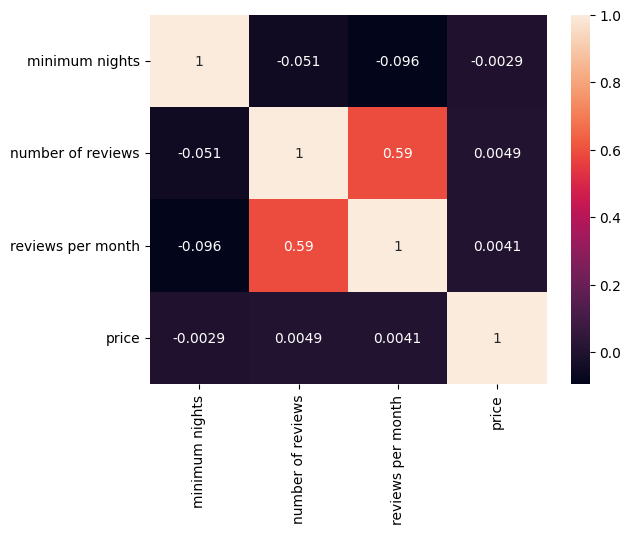

In [51]:
numerical = list(df.select_dtypes(include='number').columns)
sns.heatmap(df[numerical].corr(), annot=True)
plt.show()

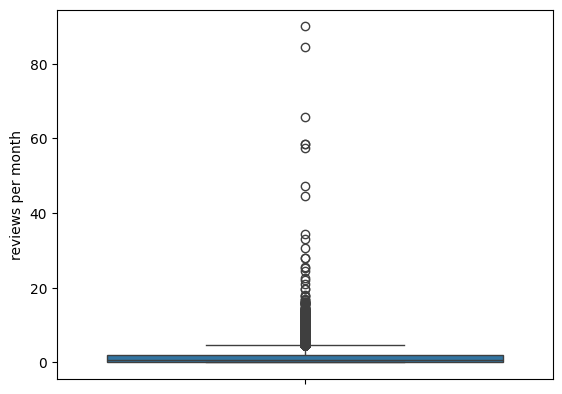

In [52]:
sns.boxplot(df['reviews per month'])
plt.show()

In [53]:
# هنا القيم الفاضية مش قليلة و مش كتيؤة اوي فهنبدل مكانهم بقيمة
# we used median not mean because there are outliers in "revies per month"
df['reviews per month'] = df['reviews per month'].fillna(df['reviews per month'].median())

In [54]:
df.isnull().sum()

,0
minimum nights,0
number of reviews,0
reviews per month,0
neighbourhood group,0
price,0
room type,0


## 6. Final check
Is the data ready for analysis? Prove it.

### Outliers

minimum nights


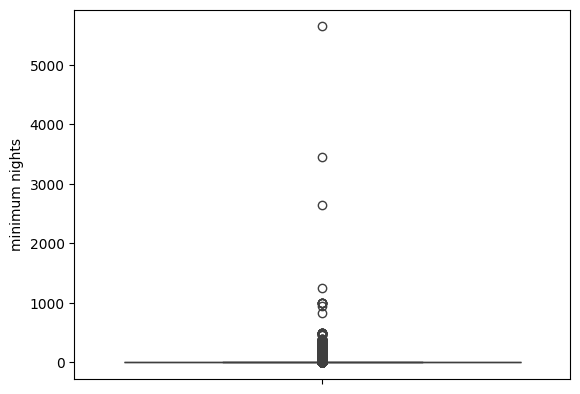

number of reviews


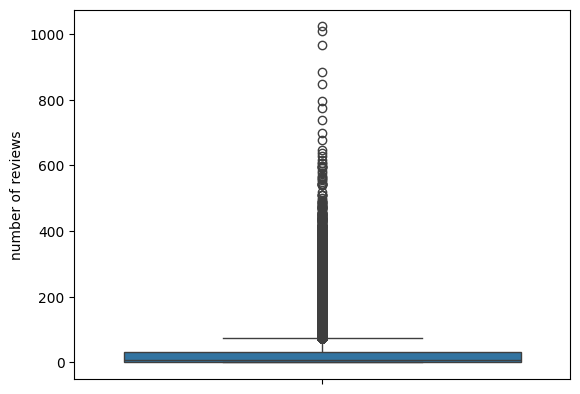

reviews per month


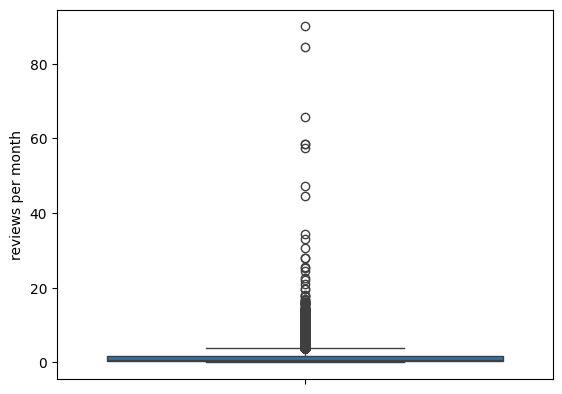

price


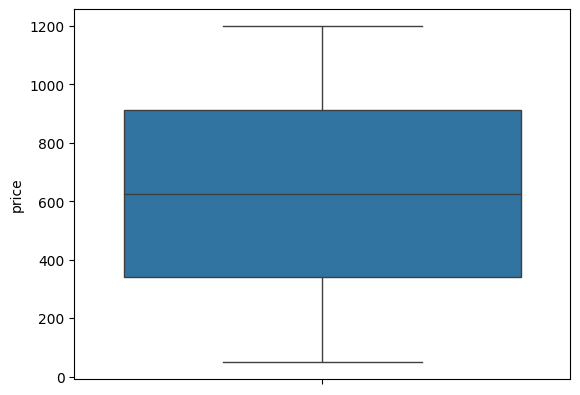

In [55]:
for col in numerical:
  print(col)
  sns.boxplot(df[col])
  plt.show()

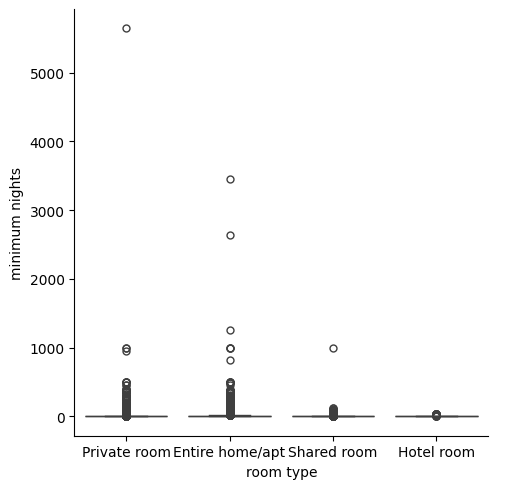

In [56]:
sns.catplot(x = 'room type', y = 'minimum nights', data = df, kind = 'box')
plt.show()

In [57]:
limits = {'minimum nights': 600, 'number of reviews': 700}

for col, limit in limits.items():
  print(col, '->', (df[col] >= limit).sum(), 'rows removed')
  df = df[df[col] < limit]

minimum nights -> 12 rows removed
number of reviews -> 8 rows removed


minimum nights


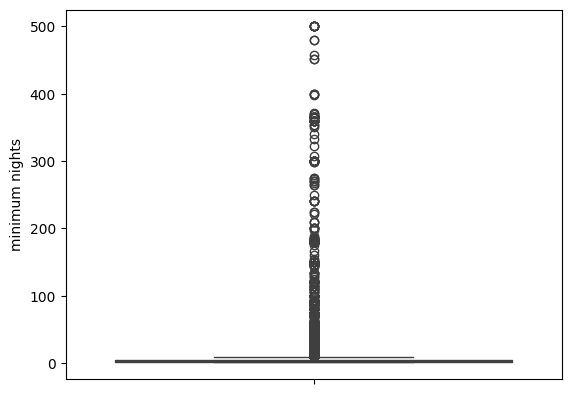

number of reviews


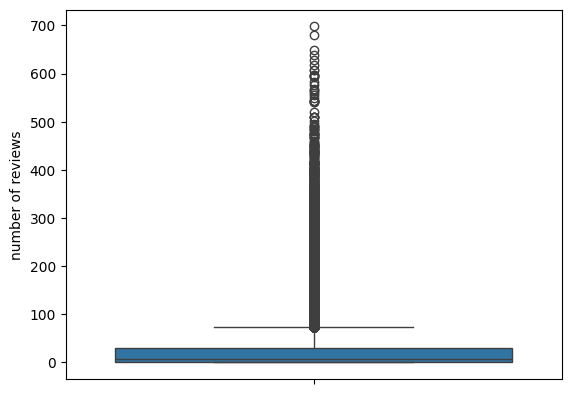

reviews per month


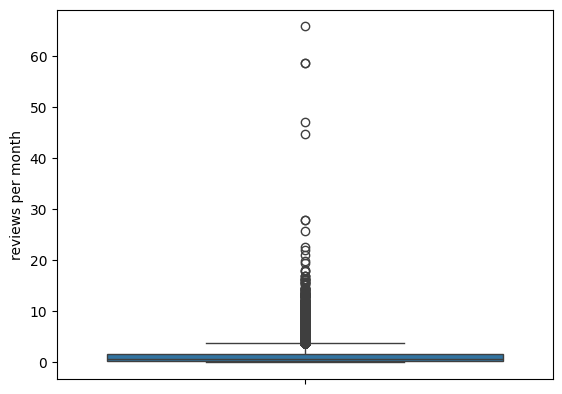

price


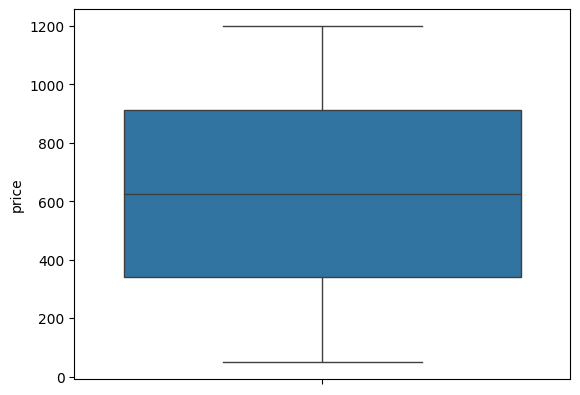

In [58]:
for col in numerical:
  print(col)
  sns.boxplot(df[col])
  plt.show()

# Preprocessing

### Encoding

In [59]:
cat

['neighbourhood group', 'room type']

In [60]:
for col in cat:
  print(col)
  print(df[col].unique())
  print('------------------------')

neighbourhood group
['brooklyn' 'manhattan' 'queens' 'staten island' 'bronx']
------------------------
room type
['Private room' 'Entire home/apt' 'Shared room' 'Hotel room']
------------------------


In [61]:
df = pd.get_dummies(df, columns=['neighbourhood group'])
df.head()

,minimum nights,number of reviews,reviews per month,price,room type,neighbourhood group_bronx,neighbourhood group_brooklyn,neighbourhood group_manhattan,neighbourhood group_queens,neighbourhood group_staten island
0,10.0,9.0,0.21,966.0,Private room,False,True,False,False,False
1,30.0,45.0,0.38,142.0,Entire home/apt,False,False,True,False,False
2,3.0,0.0,0.74,620.0,Private room,False,False,True,False,False
3,30.0,270.0,4.64,368.0,Entire home/apt,False,True,False,False,False
4,10.0,9.0,0.10,204.0,Entire home/apt,False,False,True,False,False


In [62]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['room type'] = le.fit_transform(df['room type'])
df.head()

,minimum nights,number of reviews,reviews per month,price,room type,neighbourhood group_bronx,neighbourhood group_brooklyn,neighbourhood group_manhattan,neighbourhood group_queens,neighbourhood group_staten island
0,10.0,9.0,0.21,966.0,2,False,True,False,False,False
1,30.0,45.0,0.38,142.0,0,False,False,True,False,False
2,3.0,0.0,0.74,620.0,2,False,False,True,False,False
3,30.0,270.0,4.64,368.0,0,False,True,False,False,False
4,10.0,9.0,0.10,204.0,0,False,False,True,False,False


### Scaling

In [63]:
numerical

['minimum nights', 'number of reviews', 'reviews per month', 'price']

In [64]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
df[numerical] = scaler.fit_transform(df[numerical])
df.head()

,minimum nights,number of reviews,reviews per month,price,room type,neighbourhood group_bronx,neighbourhood group_brooklyn,neighbourhood group_manhattan,neighbourhood group_queens,neighbourhood group_staten island
0,0.018036,0.012894,0.003043,0.796522,2,False,True,False,False,False
1,0.058116,0.064470,0.005629,0.080000,0,False,False,True,False,False
2,0.004008,0.000000,0.011106,0.495652,2,False,False,True,False,False
3,0.058116,0.386819,0.070440,0.276522,0,False,True,False,False,False
4,0.018036,0.012894,0.001369,0.133913,0,False,False,True,False,False


🔴 Note: the right practice is to apply scaler on train and test separately not on the entire data. This is just for learning the syntax.

### Model

In [65]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
X = df.drop('price', axis=1)
y = df['price']

model.fit(X,y)

LinearRegression()